In [158]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

#Imports all of the required libraries ^^^ [NOTE : Doesn't work if the libraries aren't already installed]


In [159]:
#Importing our dataset [https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset]

df=pd.read_csv('diabetes_prediction_dataset.csv')

#Just checking/inspecting
display(df.head()) #Prints first 5 rows
print(df.shape , '\n') #Prints dimensions of the dataset
df.info() # Prints a basic summary of dataset metadata
print('\n',df.dtypes) # Checking data types of each column


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


(100000, 9) 

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB

 gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes           

In [160]:
#Data Pre-Processing & Cleaning ->

#Checking for missing values 
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

#Dropping rows with missing values(If Any)
df=df.dropna()

# Checking for duplicate records
print("\nNumber of duplicate records:", df.duplicated().sum())

#Dropping Duplicate Rows(If Any)
df = df.drop_duplicates()
print("\nDataset dimensions after cleaning:", df.shape)


Missing values in each column:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Total missing values: 0

Number of duplicate records: 3854

Dataset dimensions after cleaning: (96146, 9)


In [161]:
# Calculating basic statistical measures

print("Mean:\n", df.mean(numeric_only=True))
print("\nMedian:\n", df.median(numeric_only=True))
print("\nStandard Deviation:\n", df.std(numeric_only=True))

# Calculating covariance between numerical features
display(df.cov(numeric_only=True))

# Calculating correlation between numerical features
display(df.corr(numeric_only=True))


Mean:
 age                     41.794326
hypertension             0.077601
heart_disease            0.040803
bmi                     27.321461
HbA1c_level              5.532609
blood_glucose_level    138.218231
diabetes                 0.088220
dtype: float64

Median:
 age                     43.00
hypertension             0.00
heart_disease            0.00
bmi                     27.32
HbA1c_level              5.80
blood_glucose_level    140.00
diabetes                 0.00
dtype: float64

Standard Deviation:
 age                    22.462948
hypertension            0.267544
heart_disease           0.197833
bmi                     6.767716
HbA1c_level             1.073232
blood_glucose_level    40.909771
diabetes                0.283616
dtype: float64


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
age,504.584014,1.546357,1.059658,52.416958,2.572780,105.051869,1.687810
hypertension,1.546357,0.071580,0.006351,0.268178,0.023385,0.928522,0.014850
heart_disease,1.059658,0.006351,0.039138,0.082175,0.014467,0.573268,0.009578
bmi,52.416958,0.268178,0.082175,45.801974,0.613190,25.621901,0.412547
HbA1c_level,2.572780,0.023385,0.014467,0.613190,1.151827,7.534885,0.123705
blood_glucose_level,105.051869,0.928522,0.573268,25.621901,7.534885,1673.609393,4.923428
diabetes,1.687810,0.014850,0.009578,0.412547,0.123705,4.923428,0.080438


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
age,1.000000,0.257305,0.238451,0.344797,0.106719,0.114317,0.264927
hypertension,0.257305,1.000000,0.119982,0.148111,0.081441,0.084834,0.195710
heart_disease,0.238451,0.119982,1.000000,0.061376,0.068140,0.070832,0.170711
bmi,0.344797,0.148111,0.061376,1.000000,0.084423,0.092543,0.214932
HbA1c_level,0.106719,0.081441,0.068140,0.084423,1.000000,0.171615,0.406408
blood_glucose_level,0.114317,0.084834,0.070832,0.092543,0.171615,1.000000,0.424336
diabetes,0.264927,0.195710,0.170711,0.214932,0.406408,0.424336,1.000000


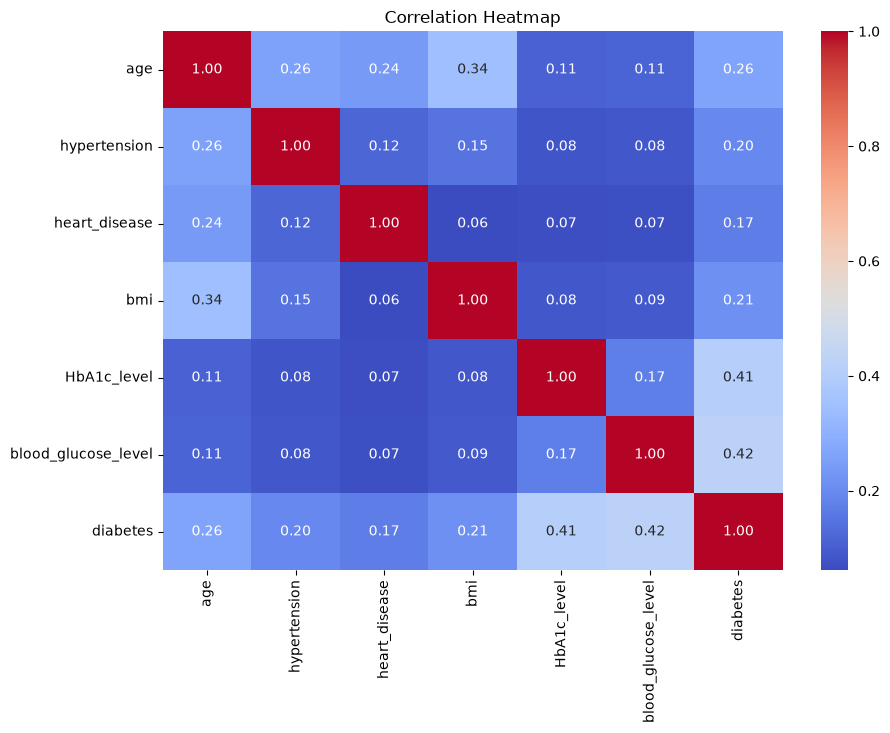

In [ ]:
# Visualizing correlations between numerical features

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()


In [163]:
# Selecting input features (independent variables)
X = df[['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']]

# Selecting target variable (dependent variable)
y = df['diabetes']

#Splitting into training and testing sets 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardizing features to bring them onto a common scale (mean = 0, standard deviation = 1)
# To prevent features with larger numerical ranges from disproportionately influencing model training
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (76916, 6)
Testing set shape: (19230, 6)
